<a href="https://colab.research.google.com/github/aseemanandi-a11y/Galactic_ISM_and_Magnetic_fields/blob/main/01-ISMTurbulence-Model/updatedgalaxy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

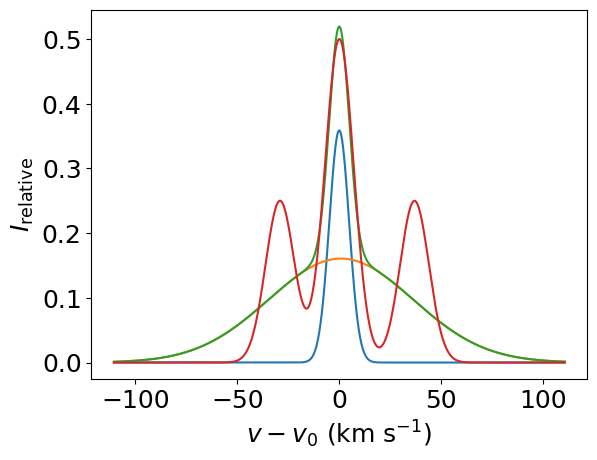

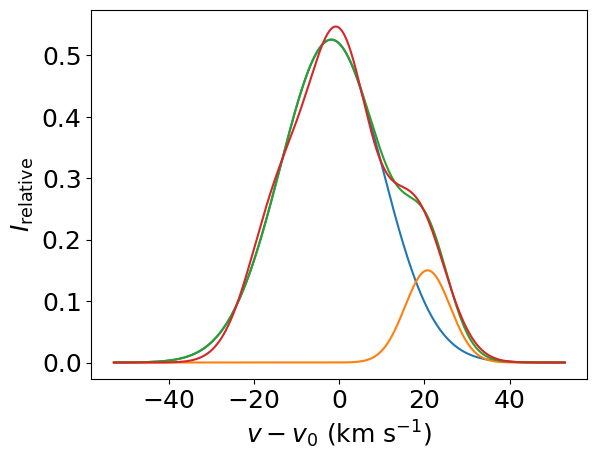

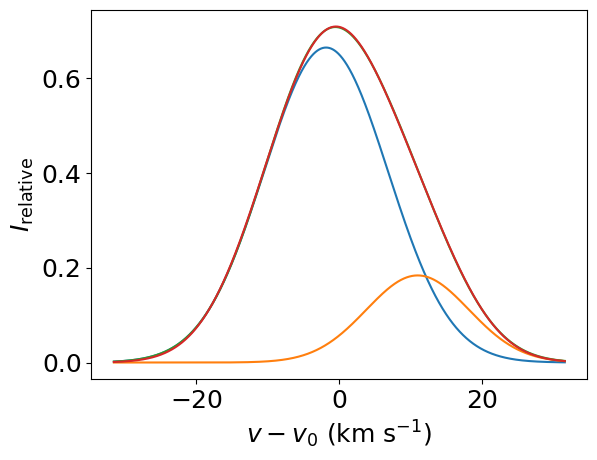

In [ ]:
#galaxy code
import numpy as np
import math
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

#update
#  i = 53 has xfar as 61.2565cos(i), 29.3556cos(i), 17.4746cos(i)
#  i = 63 has xfar as 55.2859cos(i), 33.6123cos(i), 19.4404cos(i)
#  i = 80 has xfar as 44.2755cos(i)(r=1.19kpc), 36.4822cos(i)

#48.394*np.cos(np.deg2rad(i)),
i = 53
vnvals = [48.394*np.cos(np.deg2rad(i)), 23.519*np.cos(np.deg2rad(i)), 13.842*np.cos(np.deg2rad(i))]
vfvals = [61.2565*np.cos(np.deg2rad(i)), 29.3556*np.cos(np.deg2rad(i)), 17.474*np.cos(np.deg2rad(i))]
vd = 10
fitpars = [

    (0.3476, -0.3997, 7.884,
     0.3469, 1.893, 41.57),

    (0.4119, -2.951, 11.76,
     0.3127, 6.784, 21.59),

    (0.4121, -5.667, 7.106,
     0.5642, 4.54, 10.37)
]

for j in range(0,3):
  vnear = vnvals[j]
  vfar = vfvals[j]
  vmax = max(vnear, vfar)
  v_v0 = np.linspace( -3*vfar, 3*vfar, 100000)
  I1 = 0.5 * np.exp(-((v_v0**2) / vd**2))
  I2 = 0.25 * np.exp(-((v_v0 - vfar)**2) / vd**2)
  I3 = 0.25 * np.exp(-((v_v0 + vnear)**2) / vd**2)
  Itotal = I1+I2+I3   # I2 I3 denominator chk

  # #single fit
  # def gaussian(v, A, mu, sigma):
  #   return A * np.exp(-((v - mu)/sigma)**2)
  # # Fit
  # p0 = [np.max(Itotal), 0, 20]   # initial guesses
  # popt, pcov = curve_fit(gaussian, v_v0, Itotal, p0=p0)
  # A_fit, mu_fit, sigma_fit = popt
  # Ifit = gaussian(v_v0, *popt)

  # plt.plot(v_v0, I1, label='I1')
  # plt.plot(v_v0, I2, label='I2')
  # plt.plot(v_v0, I3, label='I3')

  #double gaussian fit
  def double_gaussian(v_v0, a1, b1, c1, a2, b2, c2):
    return (
        a1*np.exp(-((v_v0-b1)/c1)**2)
        +
        a2*np.exp(-((v_v0-b2)/c2)**2)
    )


  p0 = [
      np.max(Itotal)/2, -10, 10,   # first Gaussian guess
      np.max(Itotal)/2,  10, 30    # second Gaussian guess
  ]

  popt, pcov = curve_fit(
      double_gaussian,
      v_v0,
      Itotal,
      p0=p0
  )

  a1,b1,c1,a2,b2,c2 = popt

  Ifit = double_gaussian(v_v0,*popt)

  # a1,b1,c1,a2,b2,c2 = fitpars[j]
  G1 = a1*np.exp(-((v_v0-b1)/c1)**2)
  G2 = a2*np.exp(-((v_v0-b2)/c2)**2)
  Ifit = G1 + G2

  plt.plot(v_v0, G1)
  plt.plot(v_v0, G2)

  plt.plot(v_v0, Ifit)
  plt.plot(v_v0, Itotal)

  plt.xlabel(r'$v-v_0$ (km s$^{-1}$)', fontsize=18)
  plt.ylabel(r'$I_{\mathrm{relative}}$', fontsize=18)

  plt.tick_params(labelsize=18)

  plt.show()
